In [1]:
import sys
from pathlib import Path

import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QAOAAnsatz

sys.path.insert(0, str(Path.cwd().parent))
from qsegment import formulation as fm

In [2]:
P = 1
H, const = fm.ising_2zone()
n = H.num_qubits

init = QuantumCircuit(n)
init.h(range(n))
init.barrier()

ansatz = QAOAAnsatz(cost_operator=H, reps=P, initial_state=init)
ansatz.insert_barriers = True

## Block level, before transpiling

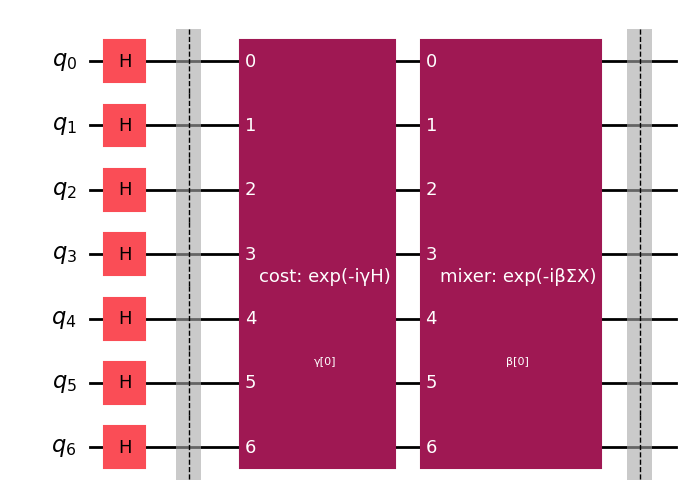

In [3]:
blocks = ansatz.decompose()
for inst in blocks.data:
    if inst.operation.name == "PauliEvolution":
        is_cost = inst.operation.params[0].name.startswith("γ")
        inst.operation.label = "cost: exp(-iγH)" if is_cost else "mixer: exp(-iβΣX)"
blocks.draw("mpl", fold=-1)

## Gate level, before transpiling

Only H, CX, Rz and Rx. No coupling map, so no routing yet. The barriers mark the end of the initial state and the end of each layer.

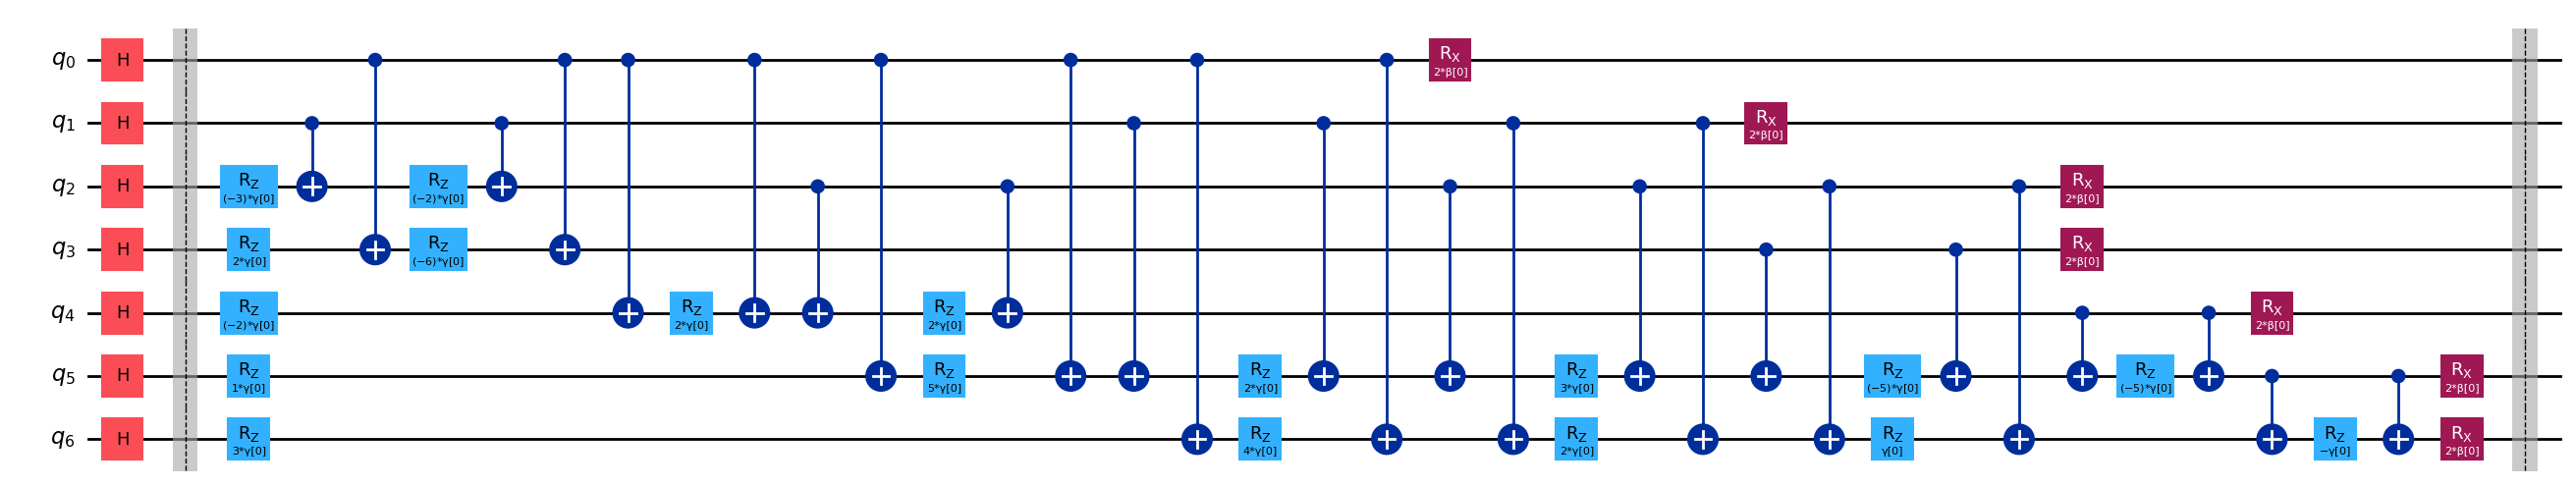

In [4]:
logical = transpile(ansatz, basis_gates=["h", "cx", "rz", "rx"], optimization_level=0)
logical.draw("mpl", fold=40)

## Gate counts

In [5]:
counts = pd.Series(logical.count_ops(), name="count").drop("barrier").to_frame()
counts.loc["depth"] = logical.depth()
counts

,count
cx,26
rz,18
h,7
rx,7
depth,27
